# Задача №1: подготовка данных и EDA временного ряда

Цель ноутбука — подготовить набор данных JOLTS/FRED к анализу,
проверить качество временной панели, сформулировать задачу
прогнозирования и выполнить базовый EDA.

## Постановка задачи

Прогнозируется `total_separations` — ежемесячное общее число
увольнений работников, в тысячах человек. Горизонт прогноза —
6 месяцев. Единица ряда — отрасль экономики США.

Данные несезонно скорректированы, поэтому сезонность исследуется
явно. Признаки `quits` и `layoffs_discharges` являются компонентами
целевой переменной, поэтому в прогнозных моделях допустимы только
их лаги или отдельные прогнозы.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from IPython.display import Image, display
import pandas as pd

from scripts.task1_eda import run_eda, FIGURES_DIR, REPORTS_DIR

## Запуск подготовки EDA

Функция `run_eda()` читает подготовленную панель, валидирует
непрерывность месячных рядов, строит таблицы EDA и сохраняет
графики в `figures/task1`.

In [2]:
results = run_eda()
data = results["data"]
summary = results["summary"]
stationarity = results["stationarity"]
stl = results["stl"]
split = results["split"]

## Размерность и качество данных

In [3]:
print(f"Rows: {len(data):,}")
print(f"Industries: {data['industry'].nunique()}")
print(f"Date range: {data['ds'].min().date()} - {data['ds'].max().date()}")
print("\nData types:")
print(data.dtypes.to_string())
print("\nMissing values:")
print(data.isna().sum().to_string())
print("\nDuplicates:", data.duplicated(["industry", "ds"]).sum())

Rows: 2,745
Industries: 9
Date range: 2000-12-01 - 2026-04-01

Data types:
industry                         str
ds                    datetime64[us]
job_openings                   int64
hires                          int64
total_separations              int64
quits                          int64
layoffs_discharges             int64

Missing values:
industry              0
ds                    0
job_openings          0
hires                 0
total_separations     0
quits                 0
layoffs_discharges    0

Duplicates: 0


In [4]:
data.head()

,industry,ds,job_openings,hires,total_separations,quits,layoffs_discharges
0,Construction,2000-12-01,172,263,480,71,384
1,Construction,2001-01-01,223,433,520,145,348
2,Construction,2001-02-01,211,380,438,146,285
3,Construction,2001-03-01,189,556,438,161,256
4,Construction,2001-04-01,285,634,436,236,169


## Описательные статистики целевого ряда

In [5]:
summary.round(3)

,industry,observations,start,end,mean,std,min,max,cv,acf_lag_1,acf_lag_12
0,Construction,305,2000-12-01,2026-04-01,376.580,82.112,208,794,0.218,0.605,0.596
1,Education and Health Services,305,2000-12-01,2026-04-01,584.508,175.626,316,1987,0.300,0.709,0.690
2,Financial Activities,305,2000-12-01,2026-04-01,205.023,43.817,106,362,0.214,0.223,0.685
3,Government,305,2000-12-01,2026-04-01,325.108,110.452,160,741,0.340,0.637,0.864
4,Information,305,2000-12-01,2026-04-01,85.656,24.185,45,232,0.282,0.405,0.488
5,Leisure and Hospitality,305,2000-12-01,2026-04-01,905.393,343.061,431,5532,0.379,0.420,0.264
6,Manufacturing,305,2000-12-01,2026-04-01,350.731,97.394,184,883,0.278,0.725,0.695
7,Professional and Business Services,305,2000-12-01,2026-04-01,973.643,168.042,536,1846,0.173,0.552,0.674
8,"Trade, Transportation, and Utilities",305,2000-12-01,2026-04-01,1063.518,215.511,673,2637,0.203,0.429,0.634


## Визуальный анализ рядов

На графиках видны различия масштаба между отраслями, сезонность и
сильные шоки периода COVID-19, особенно в Leisure and Hospitality.

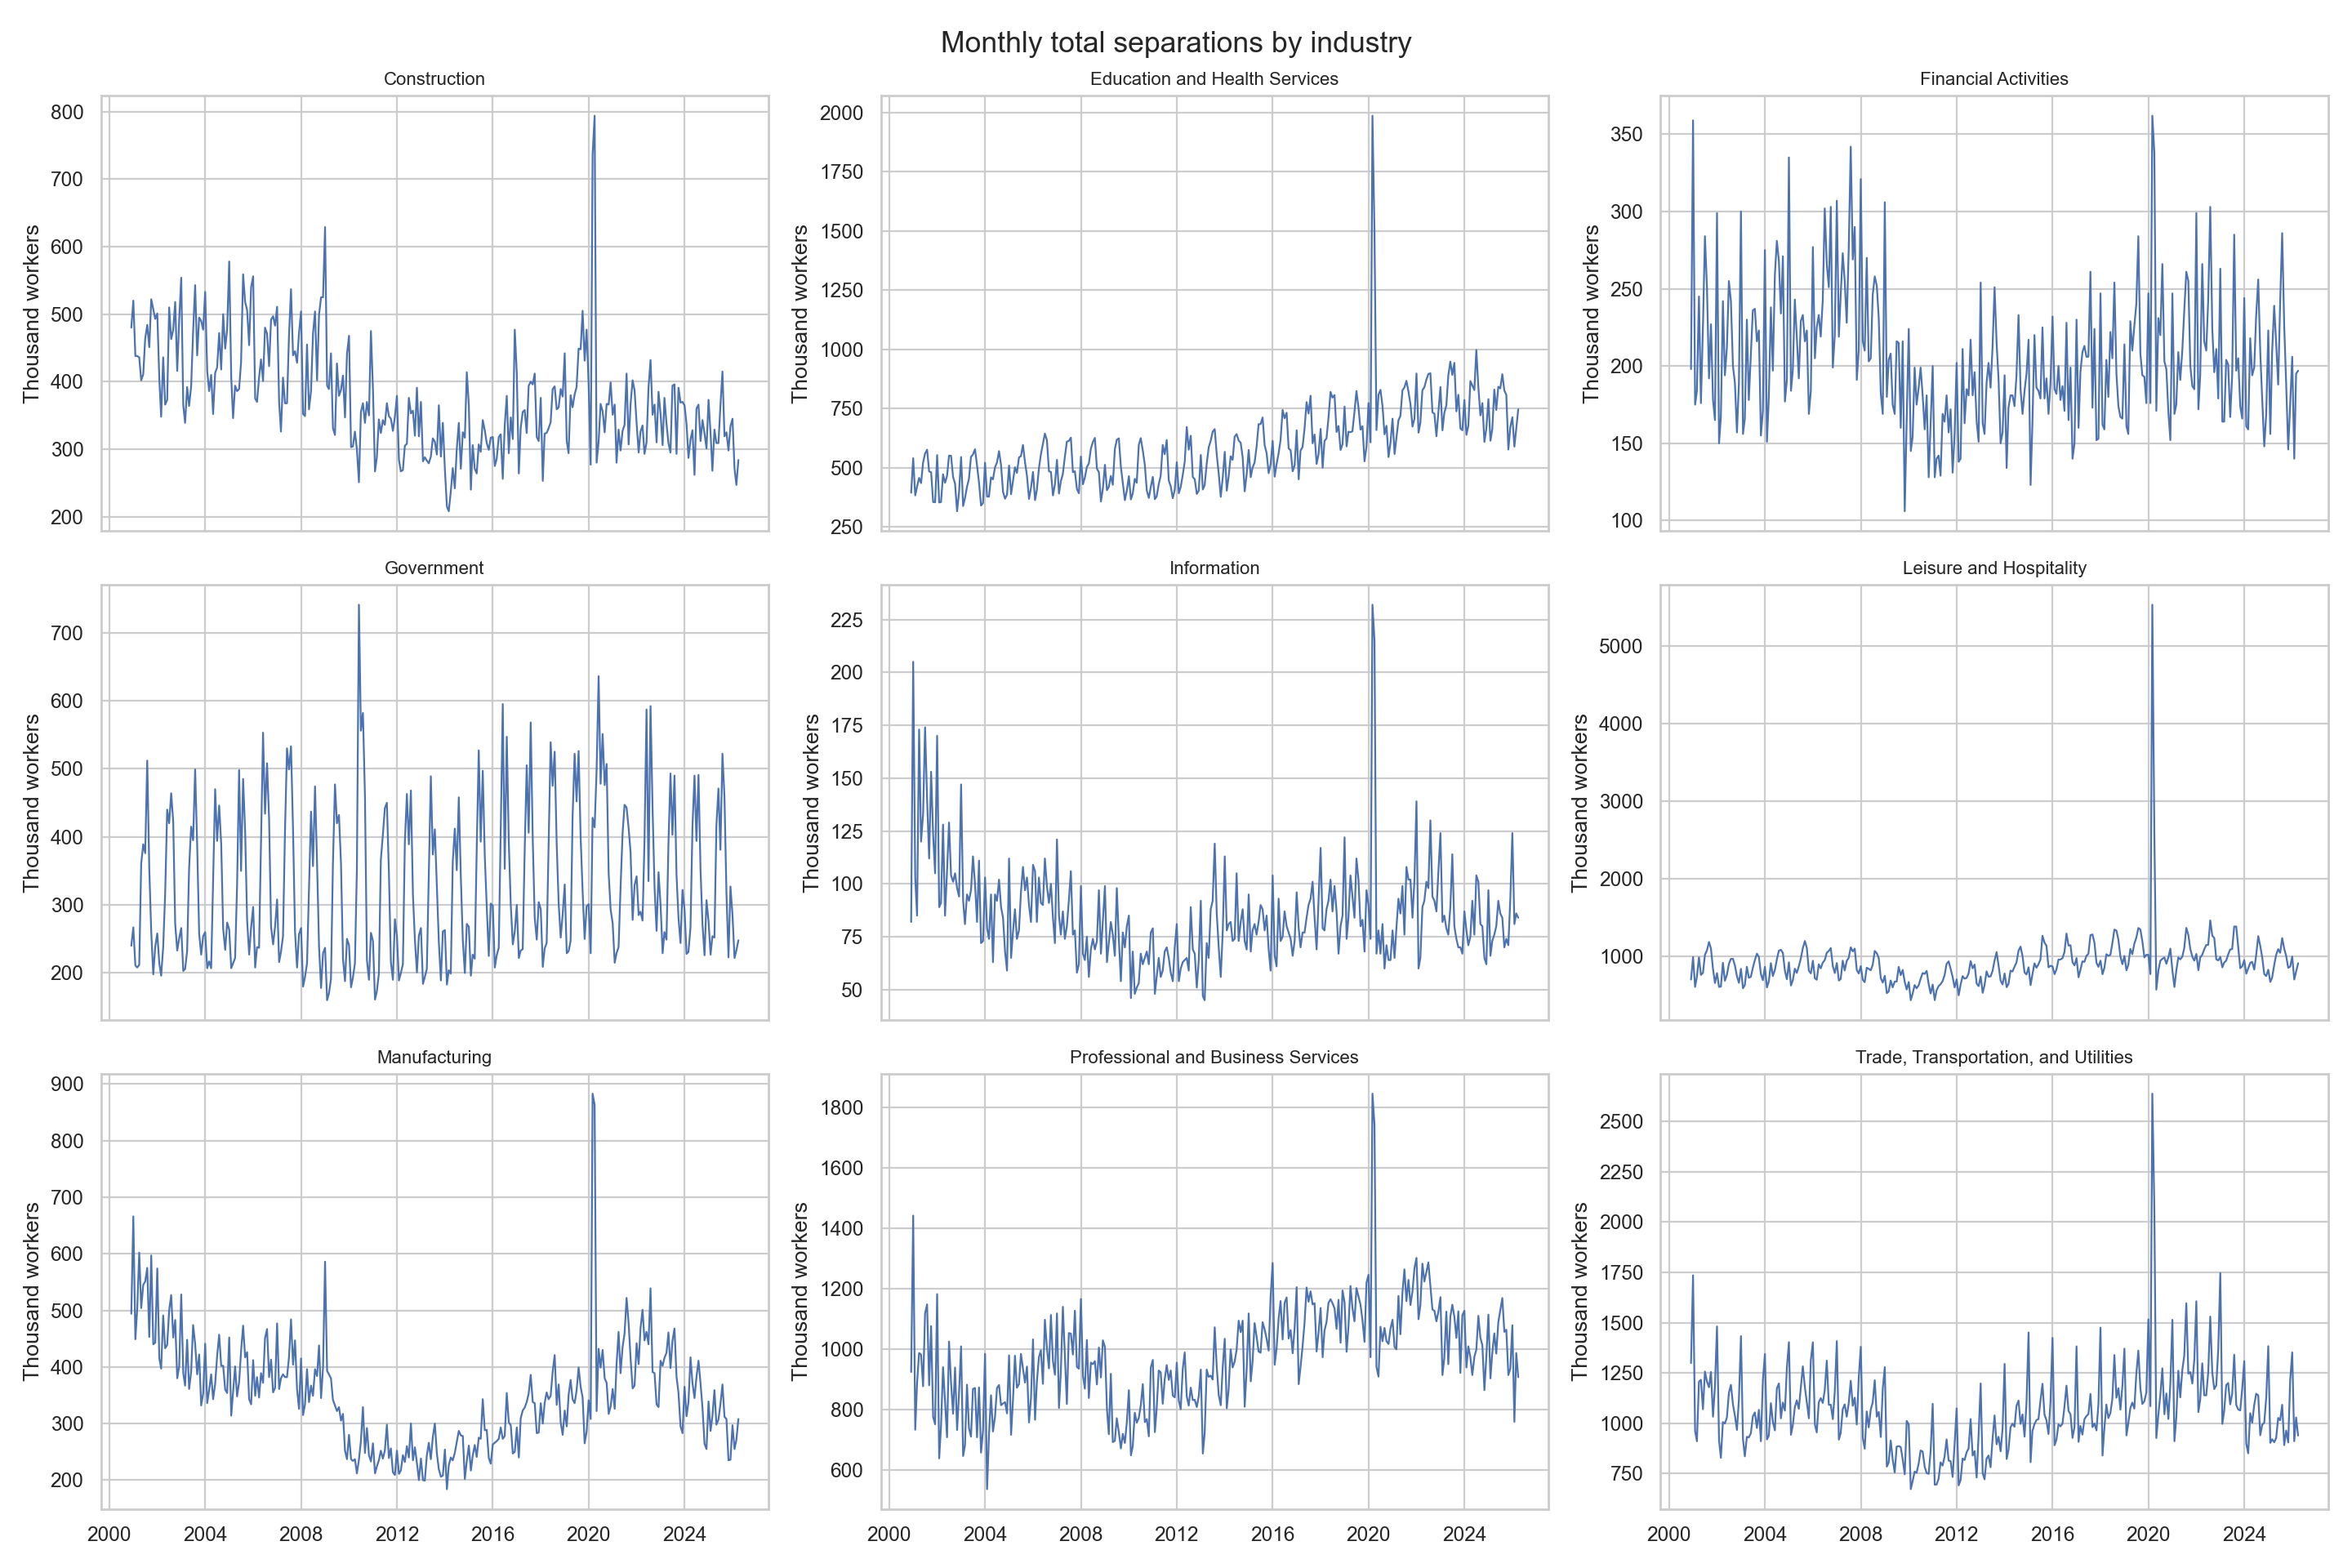

In [6]:
display(Image(filename=FIGURES_DIR / "total_separations_by_industry.png"))

## Сезонные профили

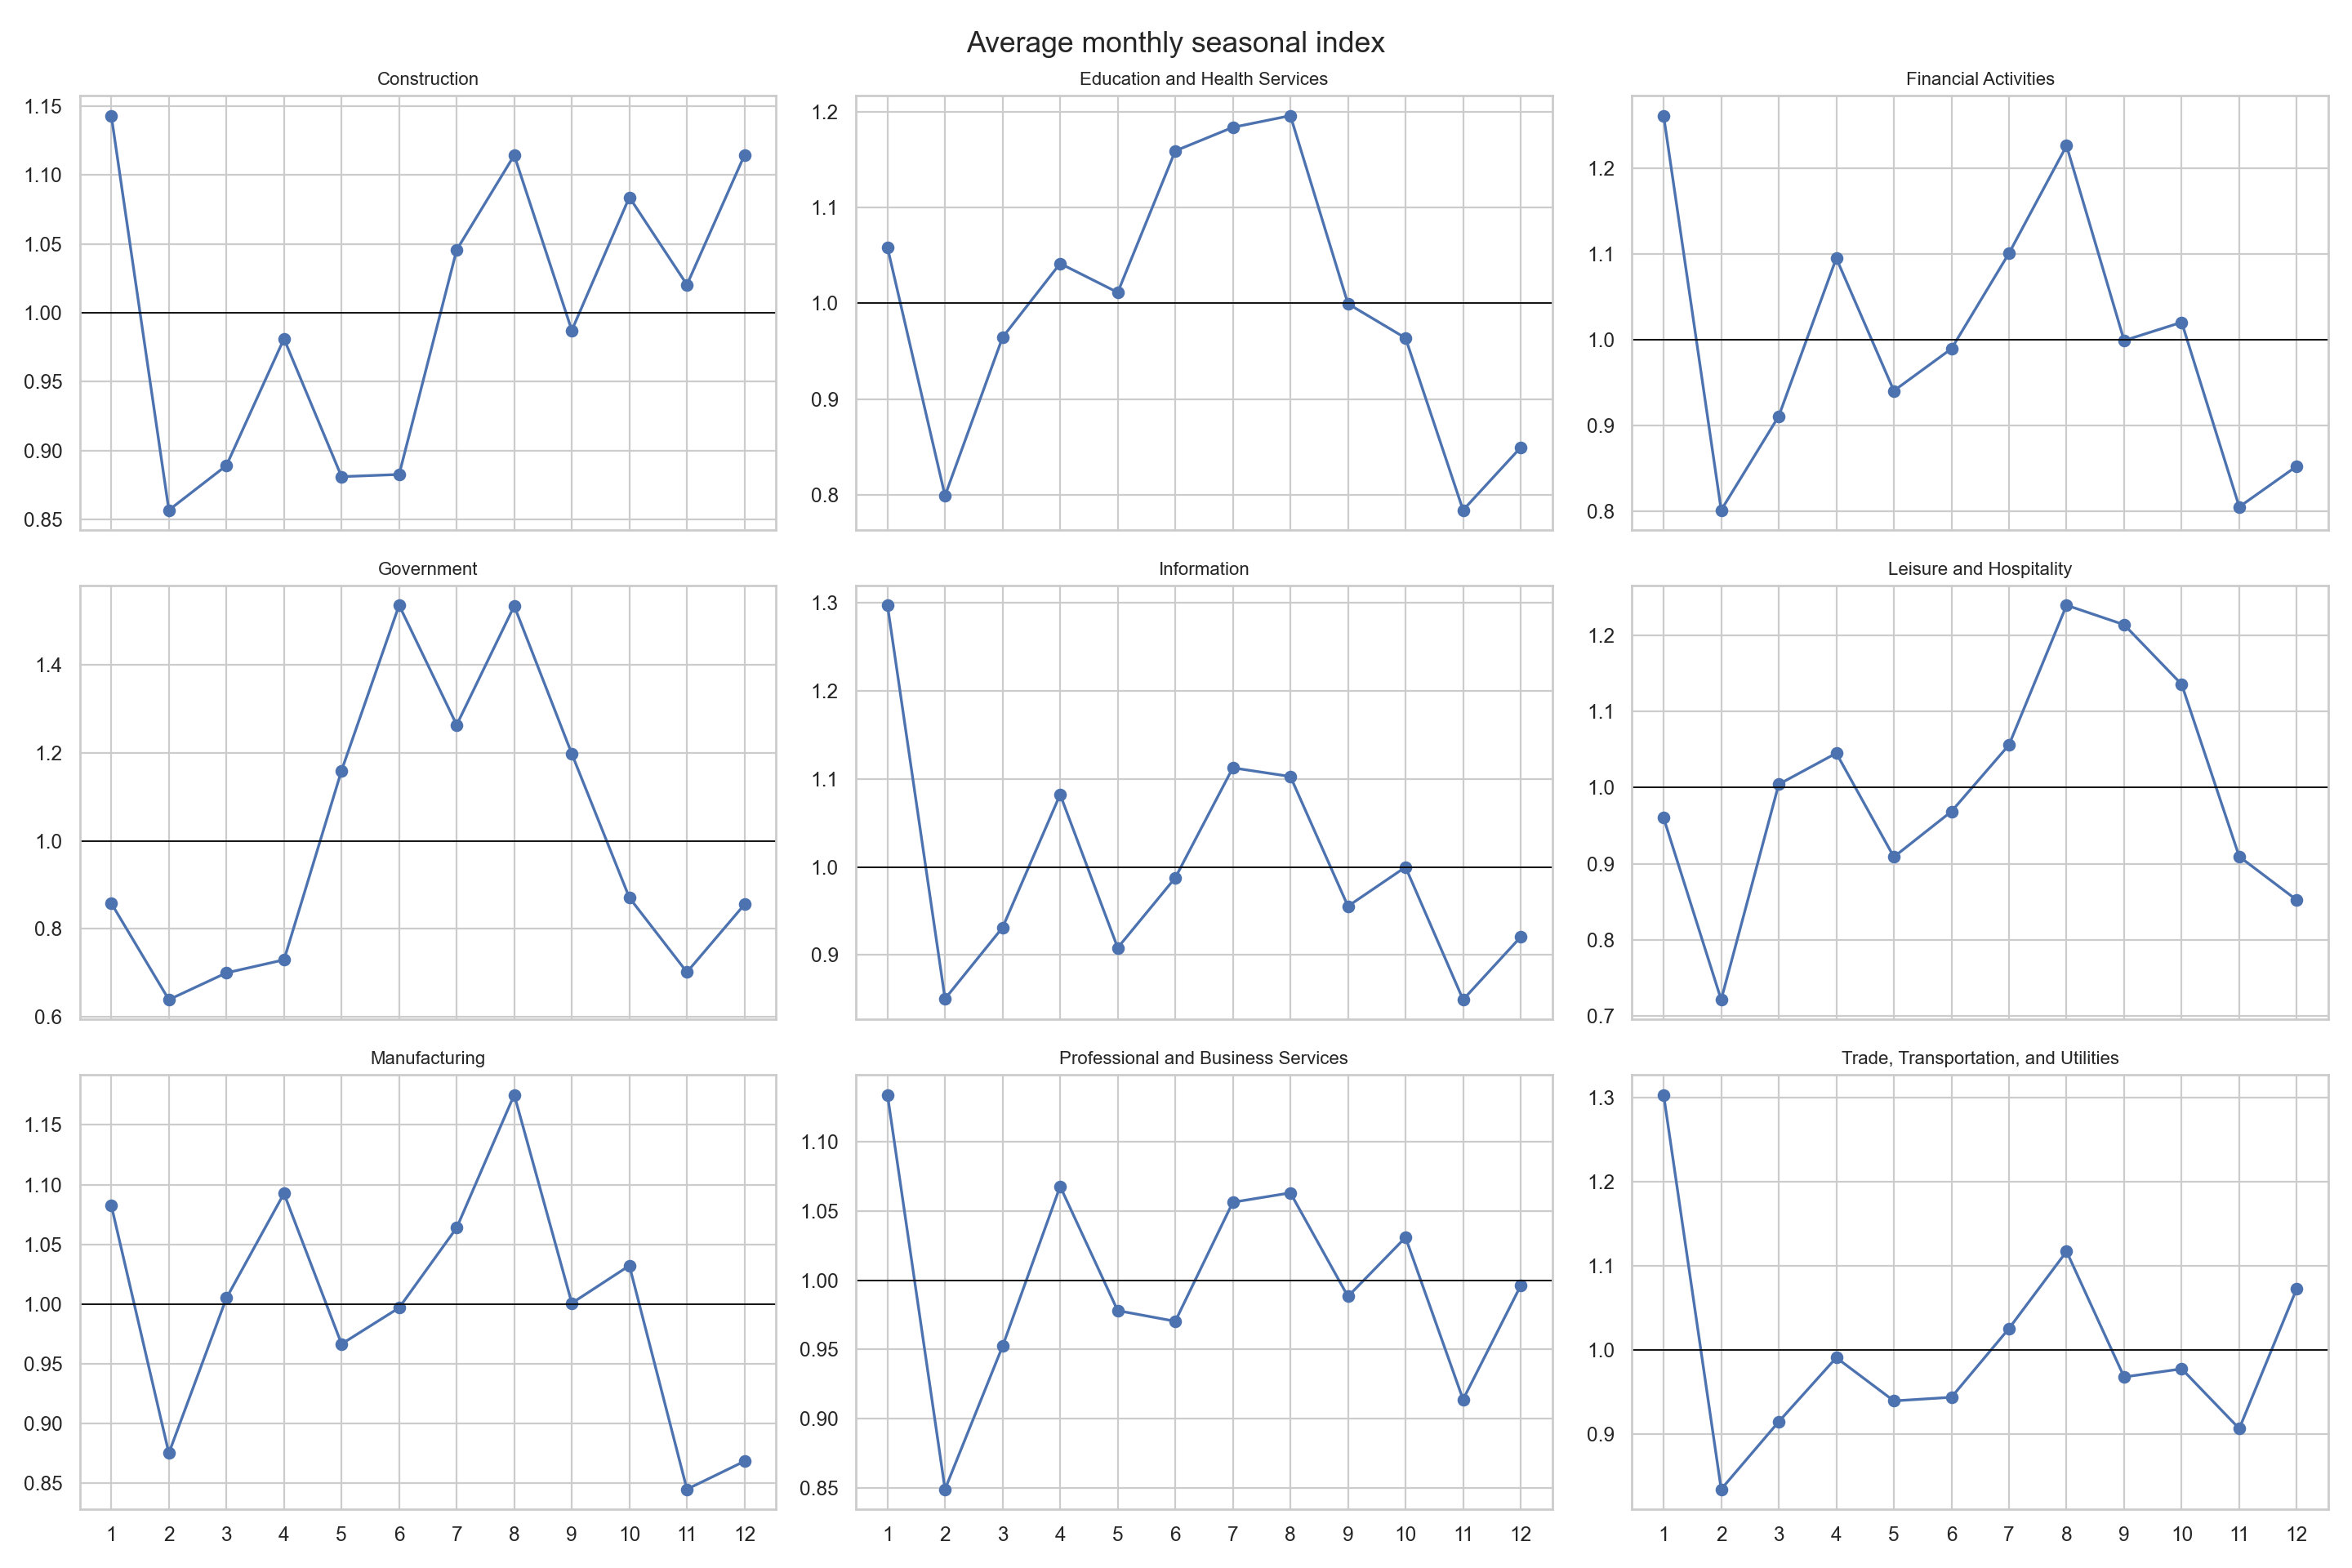

In [7]:
display(Image(filename=FIGURES_DIR / "seasonal_profiles.png"))

## STL-декомпозиция на примере Professional and Business Services

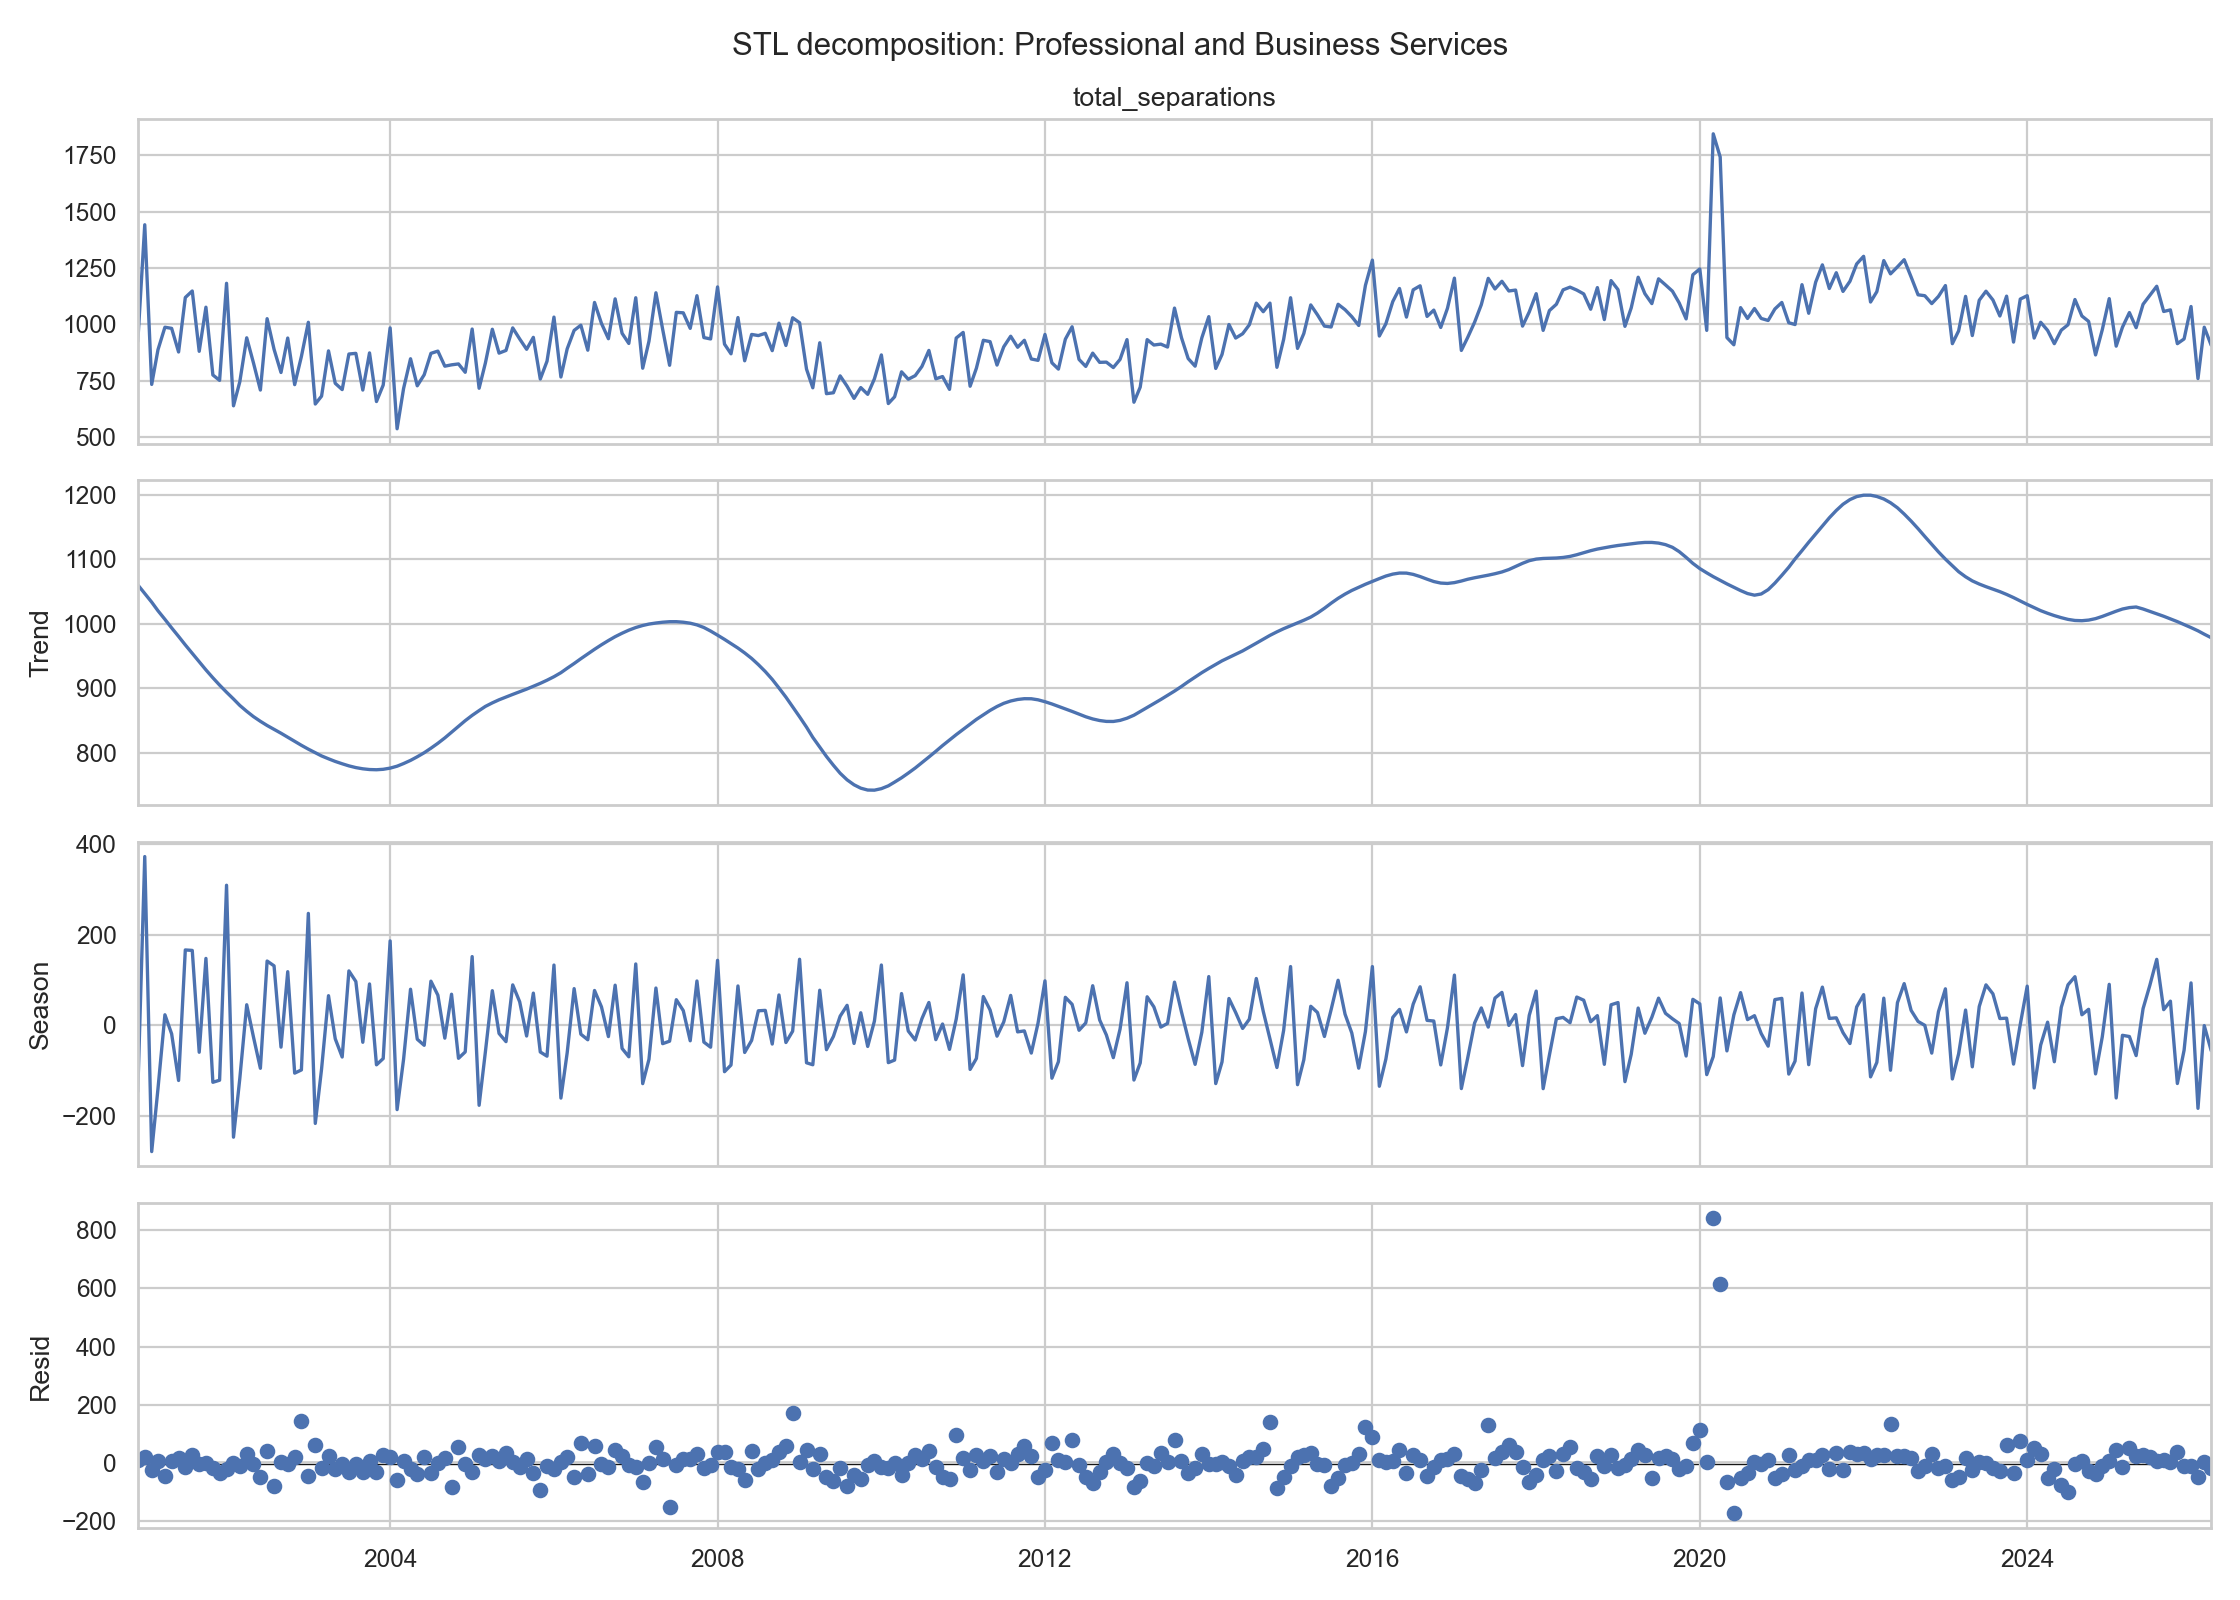

In [8]:
display(Image(filename=FIGURES_DIR / "stl_professional_business_services.png"))

In [9]:
stl.sort_values("seasonal_strength", ascending=False).round(3)

,industry,seasonal_strength,trend_strength,residual_std
3,Government,0.882,0.293,37.036
2,Financial Activities,0.732,0.582,19.292
7,Professional and Business Services,0.571,0.749,72.905
8,"Trade, Transportation, and Utilities",0.549,0.546,116.246
0,Construction,0.452,0.596,45.268
6,Manufacturing,0.444,0.741,45.045
1,Education and Health Services,0.413,0.635,94.804
4,Information,0.407,0.471,15.097
5,Leisure and Hospitality,0.155,0.206,285.273


## Проверка стационарности

In [10]:
stationarity_pivot = stationarity.pivot_table(
    index="industry",
    columns="transformation",
    values=["adf_pvalue", "kpss_pvalue"],
    aggfunc="first",
)
stationarity_pivot.round(4)

adf_pvalue                            \
transformation                           diff_1 diff_12 diff_1_12   level   
industry                                                                    
Construction                                0.0  0.0000       0.0  0.3968   
Education and Health Services               0.0  0.0000       0.0  0.7905   
Financial Activities                        0.0  0.0015       0.0  0.1375   
Government                                  0.0  0.0000       0.0  0.0155   
Information                                 0.0  0.0000       0.0  0.0026   
Leisure and Hospitality                     0.0  0.0000       0.0  0.0935   
Manufacturing                               0.0  0.0727       0.0  0.1796   
Professional and Business Services          0.0  0.0034       0.0  0.3812   
Trade, Transportation, and Utilities        0.0  0.0081       0.0  0.3337   

                                     kpss_pvalue                            
transformation                            diff_1 diff_12 diff_1_12   level  
industry                                                                    
Construction                                 0.1  0.1000       0.1  0.0100  
Education and Health Services                0.1  0.1000       0.1  0.0100  
Financial Activities                         0.1  0.1000       0.1  0.0597  
Government                                   0.1  0.1000       0.1  0.0782  
Information                                  0.1  0.0936       0.1  0.0375  
Leisure and Hospitality                      0.1  0.1000       0.1  0.0100  
Manufacturing                                0.1  0.1000       0.1  0.0199  
Professional and Business Services           0.1  0.1000       0.1  0.0100  
Trade, Transportation, and Utilities         0.1  0.1000       0.1  0.0222

Интерпретация: ADF отвергает гипотезу единичного корня при малом
p-value, KPSS отвергает стационарность при малом p-value. Поэтому
для уверенного вывода желательно, чтобы ADF p-value был меньше 0.05,
а KPSS p-value был не меньше 0.05.

## Описательные корреляции

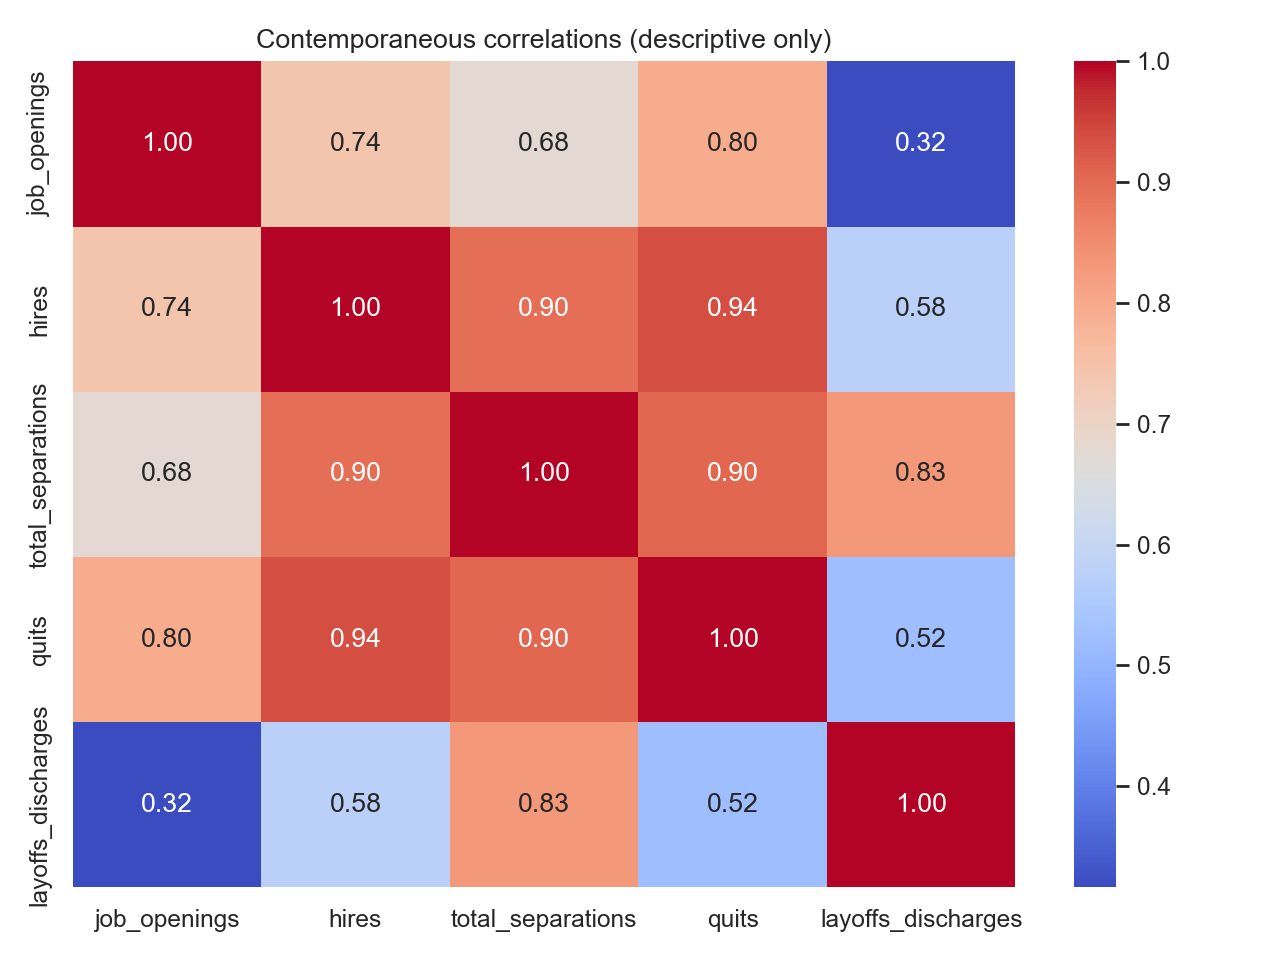

In [11]:
display(Image(filename=FIGURES_DIR / "contemporaneous_correlations.png"))

Корреляции выше являются описательными. Для прогнозирования нельзя
использовать одновременные значения `quits` и `layoffs_discharges`,
потому что они входят в состав `total_separations`.

## Train/test split для следующих задач

In [12]:
split

,industry,train_observations,train_end,test_observations,test_start,test_end
0,Construction,299,2025-10-01,6,2025-11-01,2026-04-01
1,Education and Health Services,299,2025-10-01,6,2025-11-01,2026-04-01
2,Financial Activities,299,2025-10-01,6,2025-11-01,2026-04-01
3,Government,299,2025-10-01,6,2025-11-01,2026-04-01
4,Information,299,2025-10-01,6,2025-11-01,2026-04-01
5,Leisure and Hospitality,299,2025-10-01,6,2025-11-01,2026-04-01
6,Manufacturing,299,2025-10-01,6,2025-11-01,2026-04-01
7,Professional and Business Services,299,2025-10-01,6,2025-11-01,2026-04-01
8,"Trade, Transportation, and Utilities",299,2025-10-01,6,2025-11-01,2026-04-01


## Вывод по задаче №1

In [13]:
print((REPORTS_DIR / "task1_report.md").read_text(encoding="utf-8"))

# Задача №1: подготовка данных и EDA

## Результаты проверки данных

- Панель содержит 9 отраслей и 2,745 строк.
- Каждый ряд содержит 305 ежемесячных наблюдений.
- Период: 2000-12-01 — 2026-04-01.
- Пропуски и дубликаты отсутствуют.
- Частота всех рядов: начало месяца (`MS`).
- Единица измерения: тысячи работников.

Типы данных после чтения:

| column | dtype |
|---|---|
| industry | str |
| ds | datetime64[us] |
| job_openings | int64 |
| hires | int64 |
| total_separations | int64 |
| quits | int64 |
| layoffs_discharges | int64 |

## Постановка прогноза

- Цель: `total_separations`.
- Горизонт: 6 месяцев.
- Последняя тестовая выборка: 2025-11-01 — 2026-04-01.
- Режим: offline batch forecast после выхода очередного месячного релиза.
- Основные метрики следующих этапов: MAE, RMSE и sMAPE; для сравнения отраслей
  разных масштабов дополнительно MASE.
- Локальные модели используются как отраслевые бенчмарки, потому что ряды
  различаются масштабом, сезонностью и реакцией на шоки.
- Гло